# 불균형데이터의 예측 성능

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
from IPython.core.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt


import pandas as pd
import numpy as np

from sklearn import preprocessing, model_selection, metrics, pipeline


# PR graph의 중요성
## Data Obtain

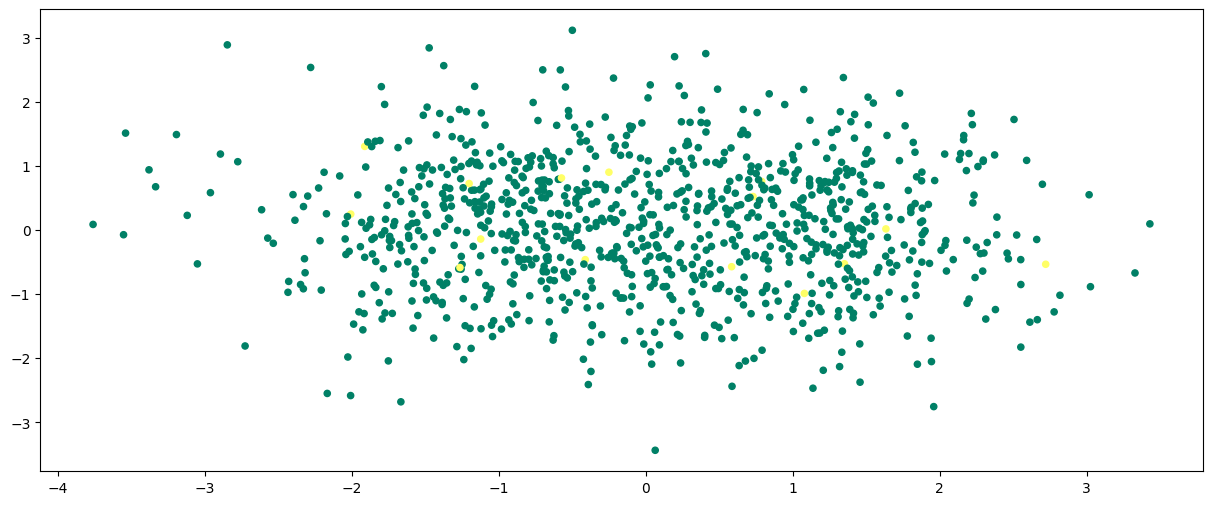

In [25]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=1000, n_classes=2, weights=[0.99, 0.01],
                          random_state=1)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='summer')

In [26]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size = 0.5,
                                                                    random_state = 2, stratify=y)
print(f'Dataset: Class 0(음성)= {len(y[y==0])} 개, Class1(양성)={len(y[y==1])} 개')

Dataset: Class 0(음성)= 985 개, Class1(양성)=15 개


In [27]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(solver='lbfgs')
y_pred = clf.fit(X_train, y_train).predict(X_test)
y_probas = clf.fit(X_train, y_train).predict_proba(X_test)
target_names = ['Negative (0)', 'Positive(1)']
print(metrics.classification_report(y_test, y_pred, target_names=target_names))

              precision    recall  f1-score   support

Negative (0)       0.99      1.00      0.99       493
 Positive(1)       0.00      0.00      0.00         7

    accuracy                           0.99       500
   macro avg       0.49      0.50      0.50       500
weighted avg       0.97      0.99      0.98       500



In [28]:
model = LogisticRegression(solver='lbfgs', class_weight='balanced')
params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
grid = model_selection.RandomizedSearchCV(model, params, cv=5, scoring= 'recall')
y_predict = grid.fit(X_train, y_train).predict(X_test)
print(metrics.classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       0.99      0.78      0.88       493
           1       0.05      0.71      0.08         7

    accuracy                           0.78       500
   macro avg       0.52      0.75      0.48       500
weighted avg       0.98      0.78      0.87       500



Text(0.5, 1.0, 'ROC Curve')

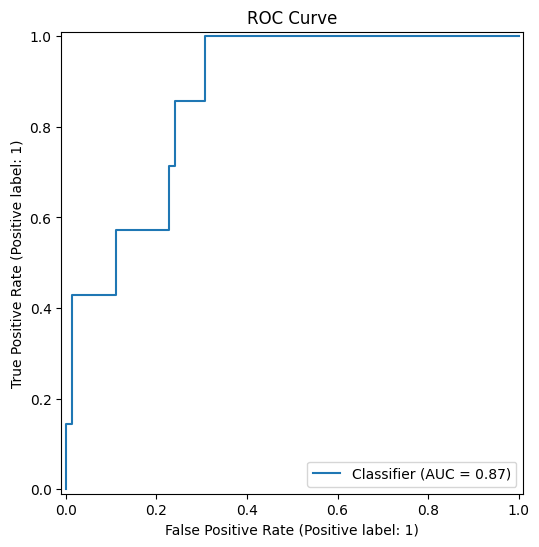

Text(0.5, 1.0, 'Precision-Recall Curve')

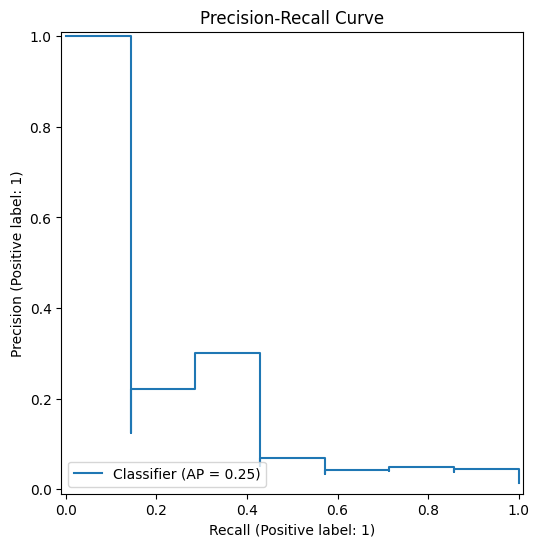

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

# Plot ROC curve
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_predictions(y_test, y_probas[:, 1], ax=ax)
ax.set_title('ROC Curve')
plt.show()

# Plot Precision-Recall curve
fig, ax = plt.subplots(figsize=(6, 6))
PrecisionRecallDisplay.from_predictions(y_test, y_probas[:, 1], ax=ax)
ax.set_title('Precision-Recall Curve')
plt.show()

## ROC와 PR curve는 다른 이야기를 하고 있으며 불균형데이터의 예측 성능지표는 AUROC보다는 PR그래프가 우수하다.
### PR 그래프는 소수 범주 자료(양성, 1%)에 집중하는 반면 ROC curve는 음성과 양성 범주 자료를 모두 고려하기 때문이다.

If we use a threshold
of 0.5 and use the logistic regression model to make a prediction for all examples in the test
set, we see that it predicts class 0 or the majority class in all cases. This can be confirmed by
using the fit model to predict crisp class labels that will use the default threshold of 0.5. The
distribution of predicted class labels can then be summarized.

### 사이킷런 내부 모델의 의사결정임계값은 '0.5'로 예측 모델의 결과인 500개는 모두 음성으로 판정한 것을 확인할 수있으며 양성판정 비율은 모두 0.22 이하인 것으로 나타남

Counter({np.int64(0): 500})

Text(0.5, 1.0, 'Histogram of Positive Probability')

Text(0.5, 0, 'Positive Probability')

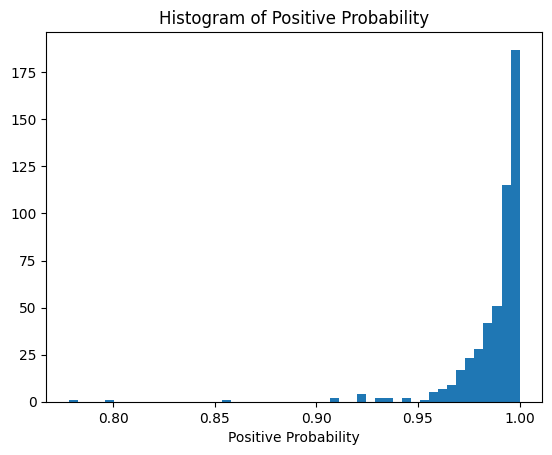

In [7]:
from collections import Counter
Counter(y_pred)
ax = plt.hist(y_probas[:, 0], bins=50)
plt.title('Histogram of Positive Probability')
plt.xlabel('Positive Probability')

Counter({np.int64(0): 500})

Text(0.5, 1.0, 'Histogram of Positive Probability')

Text(0.5, 0, 'Positive Probability')

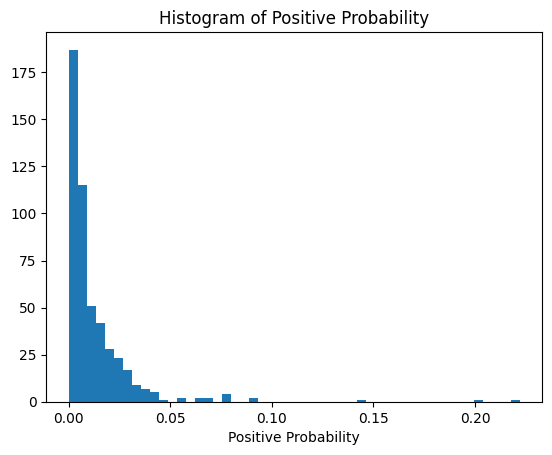

In [8]:
from collections import Counter
Counter(y_pred)
ax = plt.hist(y_probas[:, 1], bins=50)
plt.title('Histogram of Positive Probability')
plt.xlabel('Positive Probability')

<Figure size 1000x600 with 0 Axes>

(array([  1.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   2.,   0.,   0.,   4.,
          0.,   2.,   2.,   0.,   2.,   0.,   1.,   5.,   7.,   9.,  17.,
         23.,  28.,  42.,  51., 115., 187.]),
 array([0.77813693, 0.78257343, 0.78700993, 0.79144643, 0.79588293,
        0.80031942, 0.80475592, 0.80919242, 0.81362892, 0.81806542,
        0.82250191, 0.82693841, 0.83137491, 0.83581141, 0.8402479 ,
        0.8446844 , 0.8491209 , 0.8535574 , 0.8579939 , 0.86243039,
        0.86686689, 0.87130339, 0.87573989, 0.88017639, 0.88461288,
        0.88904938, 0.89348588, 0.89792238, 0.90235888, 0.90679537,
        0.91123187, 0.91566837, 0.92010487, 0.92454136, 0.92897786,
        0.93341436, 0.93785086, 0.94228736, 0.94672385, 0.95116035,
        0.95559685, 0.96003335, 0.96446985, 0.96890634, 0.97334284,
        0.97777934, 0.98221584, 0.98665234, 0.

(array([187., 115.,  51.,  42.,  28.,  23.,  17.,   9.,   7.,   5.,   1.,
          0.,   2.,   0.,   2.,   2.,   0.,   4.,   0.,   0.,   2.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   1.,   0.,   0.,   0.,   1.]),
 array([3.81711418e-05, 4.47466904e-03, 8.91116694e-03, 1.33476648e-02,
        1.77841627e-02, 2.22206606e-02, 2.66571585e-02, 3.10936564e-02,
        3.55301543e-02, 3.99666522e-02, 4.44031501e-02, 4.88396480e-02,
        5.32761459e-02, 5.77126438e-02, 6.21491417e-02, 6.65856396e-02,
        7.10221375e-02, 7.54586354e-02, 7.98951333e-02, 8.43316312e-02,
        8.87681291e-02, 9.32046270e-02, 9.76411249e-02, 1.02077623e-01,
        1.06514121e-01, 1.10950619e-01, 1.15387117e-01, 1.19823614e-01,
        1.24260112e-01, 1.28696610e-01, 1.33133108e-01, 1.37569606e-01,
        1.42006104e-01, 1.46442602e-01, 1.50879100e-01, 1.55315598e-01,
        1.

Text(0.5, 1.0, 'Histogram of Class 0 and Class 1 Probabilities')

Text(0.5, 0, 'Probability')

Text(0, 0.5, 'Frequency')

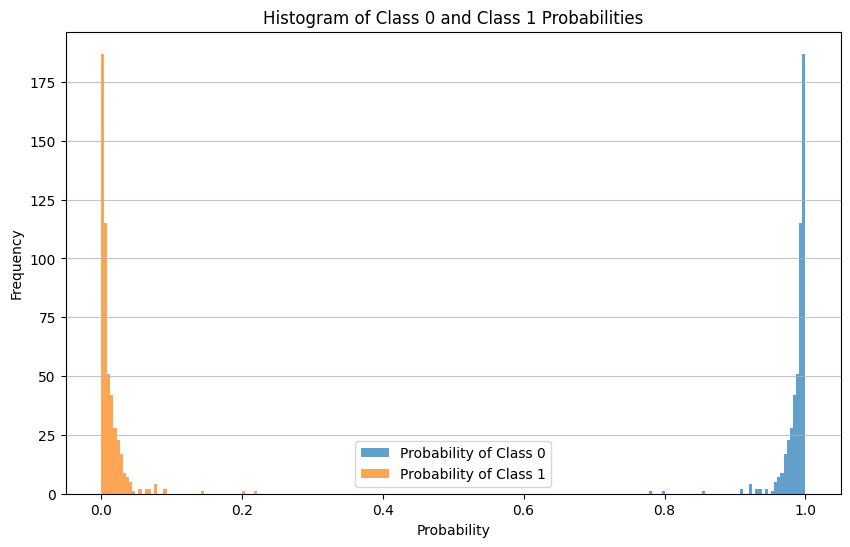

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(y_probas[:, 0], bins=50, alpha=0.7, label='Probability of Class 0')
plt.hist(y_probas[:, 1], bins=50, alpha=0.7, label='Probability of Class 1')
plt.title('Histogram of Class 0 and Class 1 Probabilities')
plt.xlabel('Probability')
plt.ylabel('Frequency')
plt.legend()
plt.grid(axis='y', alpha=0.75)
plt.show()

# Imbalanced_classification

## Probability Threshold Moving
## 1.  Optimal Threshold for ROC Curve

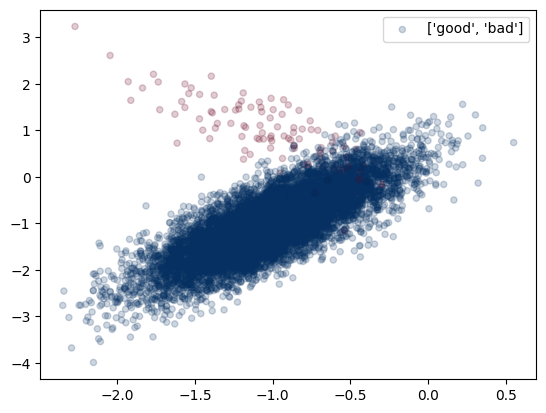

In [10]:
X, y = make_classification(n_samples=10000, n_features=5, n_redundant=3,
                           n_clusters_per_class=1, weights=[0.99], flip_y=0, random_state=4)
plt.scatter(X[:, 0], X[:, 1], c=y, s=20, cmap='RdBu_r', alpha=0.2, label=['good','bad'])
plt.legend()

The Geometric Mean or G-mean is a metric for imbalanced classification that, if optimized, will seek a balance between the sensitivity and
the specificity. One approach would be to test the model with each threshold returned from the call roc auc score() and select the threshold with the largest G-mean value.

In [11]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.5, random_state=2, stratify=y)
model = LogisticRegression(solver='lbfgs')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_probas = model.predict_proba(X_test)
print(metrics.classification_report(y_test, y_pred, target_names=target_names))

LogisticRegression()

              precision    recall  f1-score   support

Negative (0)       1.00      1.00      1.00      4950
 Positive(1)       0.97      0.56      0.71        50

    accuracy                           1.00      5000
   macro avg       0.98      0.78      0.85      5000
weighted avg       1.00      1.00      0.99      5000



Text(0.5, 0, 'Probability')

Text(0, 0.5, 'Frequency')

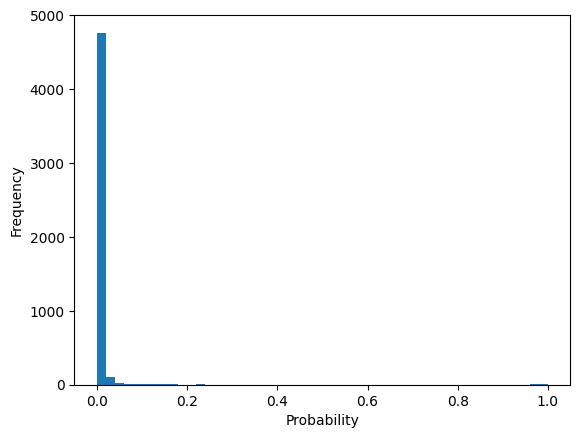

In [12]:
ax = plt.hist(y_probas[:, 1], bins=50)
plt.xlabel('Probability')
plt.ylabel('Frequency')

Best Threshold=0.017980914251173166, G-mean=0.9283416299068904


Text(0.5, 0, 'False Positive Rate')

Text(0, 0.5, 'True Positive Rate')

Best Threshold=0.017980914251173166, G-mean=0.9283416299068904


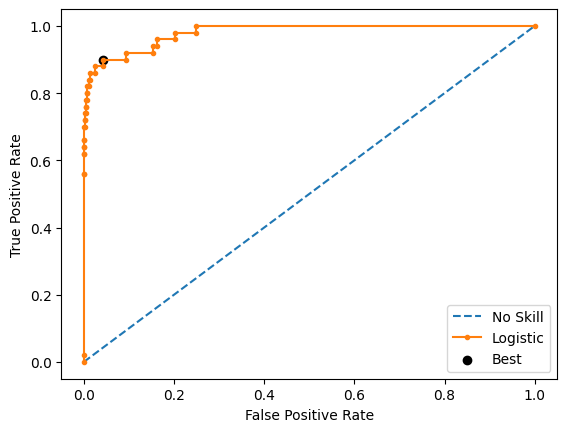

In [13]:
fpr, tpr, thresholds = metrics.roc_curve(y_test, y_probas[:, 1])
gmeans = np.sqrt(tpr * (1-fpr)) # calculate the g-mean for each threshold
ix = np.argmax(gmeans) # locate the index of the largest g-mean
print(f'Best Threshold={thresholds[ix]}, G-mean={gmeans[ix]}')

plt.plot([0,1], [0,1], linestyle='--', label='No Skill')
plt.plot(fpr, tpr, marker='.', label='Logistic')
plt.scatter(fpr[ix], tpr[ix], marker='o', color='black', label='Best')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend()
print(f'Best Threshold={thresholds[ix]}, G-mean={gmeans[ix]}')

It turns out there is a much faster way to get the same result, called the Youden’s J statistic. The statistic is calculated as:
### J = Sensitivity + Specificity − 1 = Sensitivity + (1 − FalsePositiveRate) − 1 =  TruePositiveRate − FalsePositiveRate

In [14]:
J = tpr - fpr
ix = np.argmax(J)
best_thresh = thresholds[ix]
print(f'Best Threshold= {best_thresh}')

Best Threshold= 0.017980914251173166


## 2. Optimal Threshold for Precision-Recall Curve
### 2. 1 Unlike the ROC Curve, a precision-recall curve focuses on the performance of a classifier on the positive (minority class) only.

Best Threshold=  0.344, F-measure= 0.762


Text(0.5, 0, 'Recall')

Text(0, 0.5, 'Precision')

Best Threshold=  0.344, F-measure= 0.762


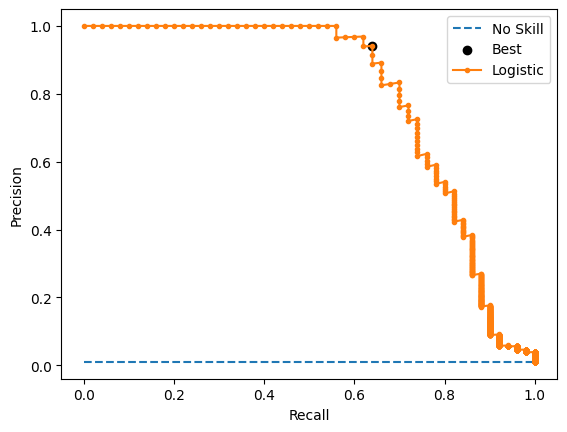

In [15]:
precision, recall, thresholds = metrics.precision_recall_curve(y_test, y_probas[:,1])
fscore = (2 * precision * recall) / (precision + recall)
ix = np.argmax(fscore) # locate the index of the largest f-measure
print(f'Best Threshold= {thresholds[ix]: .3f}, F-measure={fscore[ix]: .3f}')
no_skill = len(y_test[y_test==1]) / len(y_test)
plt.plot([0,1], [no_skill,no_skill], linestyle='--', label='No Skill')
plt.scatter(recall[ix], precision[ix], marker='o', color='black', label='Best')
plt.plot(recall, precision, marker='.', label='Logistic')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.legend()
print(f'Best Threshold= {thresholds[ix]: .3f}, F-measure={fscore[ix]: .3f}')

### 2.2. Optimal Threshold Tuning
Sometimes, we simply have a model and we wish to know the best threshold directly. In this case, we can define a set of thresholds and then evaluate predicted probabilities under each in order to find and select the optimal threshold.

In [16]:
def to_labels(pos_probs, threshold):
    return (pos_probs >= threshold).astype('int')

probs = y_probas[:, 1] # keep probabilities for the positive outcome only
thresholds = np.arange(0, 1, 0.001)
p, r, thresholds = metrics.precision_recall_curve(y_test, probs)

# Fix: Use pd.concat instead of .append()
pd.concat([
    pd.DataFrame(np.vstack([p, r]), index=['정밀도', '재현율']).round(2),
    pd.DataFrame([thresholds], columns=[f'분류임계값_{i}' for i in range(len(thresholds))], index=['분류임계값']).round(2)
])

,0,1,2,3,4,5,6,7,8,9,...,분류임계값_4990,분류임계값_4991,분류임계값_4992,분류임계값_4993,분류임계값_4994,분류임계값_4995,분류임계값_4996,분류임계값_4997,분류임계값_4998,분류임계값_4999
정밀도,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,0.01,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
재현율,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
분류임계값,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.97,0.98,0.98,0.99,0.99,1.0,1.0,1.0,1.0,1.0


### 분류임계값에 따라 Positive 판정율 내리는 비율
- 재현율과 정밀도가 교차하는 지점이 오른쪽에 있을 수록 better estimator

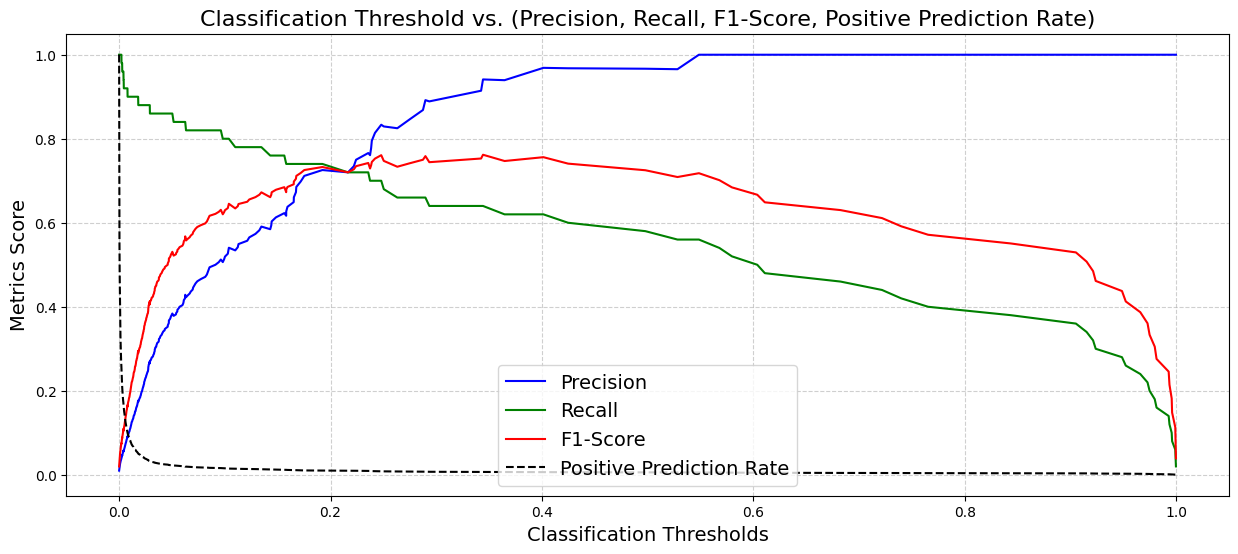

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# 기존 계산식 유지
scores = [np.sum(to_labels(probs, t)) / len(probs) for t in thresholds]

def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.rcParams["figure.figsize"] = (15, 6)

    # 제목 변경: Classification Threshold vs. Metrics
    plt.title('Classification Threshold vs. (Precision, Recall, F1-Score, Positive Prediction Rate)', fontsize='16')

    # 각 그래프 선의 라벨 변경
    plt.plot(thresholds, precisions[:-1], 'b-', label='Precision')
    plt.plot(thresholds, recalls[:-1], 'g-', label='Recall')

    # F1-Score 계산 및 라벨 변경
    f1_scores = (2 * precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1])
    plt.plot(thresholds, f1_scores, 'r-', label='F1-Score')

    # 양성판정비율 라벨 변경 (Positive Prediction Rate 또는 Positive Rate)
    plt.plot(thresholds, scores, 'k--', label='Positive Prediction Rate')

    # 축 이름 변경
    plt.ylabel('Metrics Score', fontsize='14')
    plt.xlabel('Classification Thresholds', fontsize='14')

    # 범례 및 그리드 설정
    plt.legend(loc='best', fontsize='14')
    plt.grid(True, linestyle='--', alpha=0.6) # 시각적 가독성을 위한 그리드 추가

plot_precision_recall_vs_threshold(p, r, thresholds)

## 다양한 metrics로 Tuning

In [18]:
ftwo_scorer = metrics.make_scorer(metrics.fbeta_score, beta=2)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'recall_macro', ftwo_scorer]

params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
for score in scoring:
    grid = model_selection.RandomizedSearchCV(model, param_distributions=params, cv=5, scoring= score)
    print(f'예측 성능 지표= {score}')
    print('-'*70)
    y_predict = grid.fit(X_train, y_train).predict(X_test)
    print(metrics.classification_report(y_test, y_predict))
    print('-'*70)

예측 성능 지표= accuracy
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4950
           1       0.97      0.62      0.76        50

    accuracy                           1.00      5000
   macro avg       0.98      0.81      0.88      5000
weighted avg       1.00      1.00      1.00      5000

----------------------------------------------------------------------
예측 성능 지표= precision
----------------------------------------------------------------------
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4950
           1       0.97      0.58      0.72        50

    accuracy                           1.00      5000
   macro avg       0.98      0.79      0.86      5000
weighted avg       1.00      1.00      1.00      5000

----------------------------------------------------------------------
예측 성능 지표= recall
------

In [19]:
grid.best_estimator_

LogisticRegression(C=np.float64(10000.0))

In [20]:
from sklearn.metrics import make_scorer, recall_score, accuracy_score, precision_score, confusion_matrix
scorers = {
    'precision_score': make_scorer(precision_score),
    'recall_score': make_scorer(recall_score),
    'accuracy_score': make_scorer(accuracy_score)
}
for key, _ in scorers.items():
    print(key)
    grid = model_selection.RandomizedSearchCV(model, param_distributions=params, cv=5,
                                              scoring= scorers,
                                              refit= key)
    grid.fit(X_train, y_train)
    grid.best_estimator_

precision_score


RandomizedSearchCV(cv=5, estimator=LogisticRegression(),
                   param_distributions={'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                                        'penalty': ['l1', 'l2']},
                   refit='precision_score',
                   scoring={'accuracy_score': make_scorer(accuracy_score, response_method='predict'),
                            'precision_score': make_scorer(precision_score, response_method='predict'),
                            'recall_score': make_scorer(recall_score, response_method='predict')})

LogisticRegression(C=np.float64(11.288378916846883))

recall_score


RandomizedSearchCV(cv=5, estimator=LogisticRegression(),
                   param_distributions={'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                                        'penalty': ['l1', 'l2']},
                   refit='recall_score',
                   scoring={'accuracy_score': make_scorer(accuracy_score, response_method='predict'),
                            'precision_score': make_scorer(precision_score, response_method='predict'),
                            'recall_score': make_scorer(recall_score, response_method='predict')})

LogisticRegression(C=np.float64(1438.44988828766))

accuracy_score


RandomizedSearchCV(cv=5, estimator=LogisticRegression(),
                   param_distributions={'C': array([1.00000000e-04, 2.63665090e-04, 6.95192796e-04, 1.83298071e-03,
       4.83293024e-03, 1.27427499e-02, 3.35981829e-02, 8.85866790e-02,
       2.33572147e-01, 6.15848211e-01, 1.62377674e+00, 4.28133240e+00,
       1.12883789e+01, 2.97635144e+01, 7.84759970e+01, 2.06913808e+02,
       5.45559478e+02, 1.43844989e+03, 3.79269019e+03, 1.00000000e+04]),
                                        'penalty': ['l1', 'l2']},
                   refit='accuracy_score',
                   scoring={'accuracy_score': make_scorer(accuracy_score, response_method='predict'),
                            'precision_score': make_scorer(precision_score, response_method='predict'),
                            'recall_score': make_scorer(recall_score, response_method='predict')})

LogisticRegression(C=np.float64(1.623776739188721))

In [22]:
grid.cv_results_.keys()
# The 'rank_test_precision_score', 'rank_test_recall_score', 'rank_test_accuracy_score' keys are now directly available.
# We will use 'params', 'rank_test_accuracy_score' and 'mean_test_accuracy_score' as these are the relevant keys from the last refit.
results = pd.DataFrame(grid.cv_results_)[['params', 'rank_test_accuracy_score', 'mean_test_accuracy_score']]
results

dict_keys(['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_penalty', 'param_C', 'params', 'split0_test_precision_score', 'split1_test_precision_score', 'split2_test_precision_score', 'split3_test_precision_score', 'split4_test_precision_score', 'mean_test_precision_score', 'std_test_precision_score', 'rank_test_precision_score', 'split0_test_recall_score', 'split1_test_recall_score', 'split2_test_recall_score', 'split3_test_recall_score', 'split4_test_recall_score', 'mean_test_recall_score', 'std_test_recall_score', 'rank_test_recall_score', 'split0_test_accuracy_score', 'split1_test_accuracy_score', 'split2_test_accuracy_score', 'split3_test_accuracy_score', 'split4_test_accuracy_score', 'mean_test_accuracy_score', 'std_test_accuracy_score', 'rank_test_accuracy_score'])

,params,rank_test_accuracy_score,mean_test_accuracy_score
0,"{'penalty': 'l1', 'C': 3792.690190732246}",6,NaN
1,"{'penalty': 'l2', 'C': 1.623776739188721}",1,0.9960
2,"{'penalty': 'l2', 'C': 0.0001}",5,0.9900
3,"{'penalty': 'l2', 'C': 0.08858667904100823}",2,0.9942
4,"{'penalty': 'l1', 'C': 0.23357214690901212}",6,NaN
5,"{'penalty': 'l1', 'C': 0.03359818286283781}",6,NaN
6,"{'penalty': 'l1', 'C': 29.763514416313132}",6,NaN
7,"{'penalty': 'l2', 'C': 0.012742749857031334}",4,0.9904
8,"{'penalty': 'l2', 'C': 0.03359818286283781}",3,0.9920
9,"{'penalty': 'l1', 'C': 1.623776739188721}",6,NaN


## 손실함수 조정

In [23]:
model = LogisticRegression(solver='lbfgs', class_weight='balanced')
params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
grid = model_selection.RandomizedSearchCV(model, params, cv=5, scoring= 'recall')
y_predict = grid.fit(X_train, y_train).predict(X_test)
print(metrics.classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       1.00      0.92      0.96      4950
           1       0.11      0.92      0.19        50

    accuracy                           0.92      5000
   macro avg       0.55      0.92      0.58      5000
weighted avg       0.99      0.92      0.95      5000



In [24]:
minor = np.sum(y)/len(y); major = 1- minor
model = LogisticRegression(solver='lbfgs', class_weight= {0: minor, 1: major})
params = {'C': np.logspace(-4, 4, 20), 'penalty': ['l1', 'l2']}
grid = model_selection.RandomizedSearchCV(model, params, cv=5, scoring= 'recall')
y_predict = grid.fit(X_train, y_train).predict(X_test)
print(metrics.classification_report(y_test, y_predict))

              precision    recall  f1-score   support

           0       1.00      0.92      0.96      4950
           1       0.11      0.92      0.19        50

    accuracy                           0.92      5000
   macro avg       0.55      0.92      0.58      5000
weighted avg       0.99      0.92      0.95      5000

